# Social Structure and Community Detection

**Author: Apostolos Stefanos Tzellas**

We compare three real networks—college football, Game of Thrones season five, and institutional email—with five synthetic reference models. We then use Girvan–Newman, spectral clustering, and greedy modularity to expose communities, visualize every resulting partition, and compare structural quality with known email departments.

The objective is to distinguish **structural groups**, which have many internal connections, from **recorded organizational groups**, which may serve a different purpose. Both modularity-selected and performance-selected partitions are retained.

## Key findings

Community quality depends on the objective. On the **986-member email network**, the modularity-selected spectral partition achieves the highest modularity within the tested methods and search range:

| Modularity-selected method | Groups | Modularity | Department agreement (ARI) |
|---|---:|---:|---:|
| Spectral clustering | 11 | 0.376 | 0.207 |
| Greedy modularity | 8 | 0.347 | 0.154 |
| Girvan–Newman | 2 | 0.0006 | −0.0003 |

The recorded organization contains **42 departments**. Spectral clustering finds a stronger structural partition than the department partition, but its ARI of 0.207 indicates limited agreement with those labels. **Finding densely connected groups and recovering an organization chart are different tasks.**

The eight-network comparison also shows that geometric neighborhoods and regular ring segments can produce high-modularity groups without planted social labels. All five selected partitions per network are visualized below.


## Setup and reproducibility

Run from top to bottom in Jupyter, VS Code, or Colab. Every analysis function is defined here; no other notebook or local Python package is required. The first cell installs the dependencies. Run installation in one notebook at a time if they share a Python environment; restart the kernel if packages were replaced.

Real datasets are downloaded from the sources listed below and cached in the system temporary directory. Their SHA-256 hashes identify the snapshots used. After a cache is cleared, the next run downloads them again. Download failures stop the affected analysis explicitly; a different graph is never substituted. Edges are unweighted and undirected unless a section explicitly states otherwise.

In [ ]:
%pip install -q "numpy>=1.26,<2" "scipy>=1.11,<2" "networkx>=3.2,<4" "pandas>=2,<3" "matplotlib>=3.7,<4" "scikit-learn>=1.3,<2" tqdm "igraph>=0.11,<2"

In [1]:
from pathlib import Path
import gzip
import hashlib
import io
import json
import math
import random
import tempfile
import time
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tqdm.auto import tqdm
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})

SEED = 5

In [2]:
CACHE = Path(tempfile.gettempdir()) / "social-network-data"
CACHE.mkdir(parents=True, exist_ok=True)
SOURCES = {
    "got-s5-edges.csv": "https://raw.githubusercontent.com/mathbeveridge/gameofthrones/068e0af18cc6b71e064472e34da1aa5c27c9de8d/data/got-s5-edges.csv",
    "email-Eu-core.txt.gz": "https://snap.stanford.edu/data/email-Eu-core.txt.gz",
    "email-Eu-core-department-labels.txt.gz": "https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz",
    "football.zip": "https://websites.umich.edu/~mejn/netdata/football.zip"
}
SHA256 = {
    "got-s5-edges.csv": "70a093f78d5a17b875f38b3448ab0ba36a1fcbfaf717ea6e88d4ef2b61dab057",
    "email-Eu-core.txt.gz": "4b47acdb80197b085fe63c819c357ae488131ee904ed93d1b219a68b0f9e245f",
    "email-Eu-core-department-labels.txt.gz": "e5abe5b4581a480032a63adcf2576c161785f45692642c6ebb0b1276f0f33669",
    "football.zip": "147081ba047c919782896b26852f812e65880a9e52f69070069f950eea90c396"
}

def fetch_data(name):
    """Download once, validate the snapshot, and reuse the cached data."""
    path = CACHE / name
    if path.exists() and hashlib.sha256(path.read_bytes()).hexdigest() == SHA256[name]:
        return path
    request = urllib.request.Request(SOURCES[name], headers={"User-Agent": "NetworkAnalysis/1.0"})
    try:
        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()
    except Exception as error:
        raise RuntimeError(f"Cannot download {name} from {SOURCES[name]}. "
                           f"Check internet access and rerun this cell. Details: {error}") from error
    if hashlib.sha256(content).hexdigest() != SHA256[name]:
        raise ValueError(f"{name} differs from the documented dataset snapshot. "
                         "Inspect the source before changing its expected SHA-256.")
    # A unique temporary name also avoids conflicts between concurrently running notebooks.
    with tempfile.NamedTemporaryFile(dir=CACHE, delete=False) as temporary:
        temporary.write(content)
        temporary_path = Path(temporary.name)
    temporary_path.replace(path)
    return path

def load_got(season):
    table = pd.read_csv(fetch_data(f"got-s{season}-edges.csv"))
    graph = nx.from_pandas_edgelist(table, "Source", "Target", edge_attr="Weight")
    graph.remove_edges_from(nx.selfloop_edges(graph))
    return graph

## Loading real networks and connected reference models

| Network | Nodes and edges represent | Preprocessing |
|---|---|---|
| [Football](https://websites.umich.edu/~mejn/netdata/) | Colleges and regular-season games in fall 2000 | Read GML labels and conference attributes |
| [Game of Thrones S5](https://github.com/mathbeveridge/gameofthrones) | Characters and script-derived interactions in season five | Read CSV header; ignore interaction weights |
| [email-Eu-core](https://snap.stanford.edu/data/email-Eu-core.html) | Institution members and emails | Symmetrize directed links, remove loops, retain the largest component |

The synthetic models use 80 nodes, lattice/attachment degree four, 300 ER edges, geometric radius 0.25, WS rewiring 0.3, and seed five. All five references are connected; retries are bounded and recorded. Node identities are retained throughout, including for department-label alignment.

,nodes,edges,components,mean_degree,mean_clustering,mean_closeness
REG,80.0,160.0,1.0,4.0000,0.5000,0.0963
ER,80.0,300.0,1.0,7.5000,0.0850,0.4242
RGG,80.0,450.0,1.0,11.2500,0.6826,0.3201
BA,80.0,304.0,1.0,7.6000,0.2292,0.4464
WS,80.0,160.0,1.0,4.0000,0.1671,0.2691
Football,115.0,613.0,1.0,10.6609,0.4032,0.3993
GoT S5,119.0,396.0,1.0,6.6555,0.5744,0.3191
Email,986.0,16064.0,1.0,32.5842,0.4071,0.3945


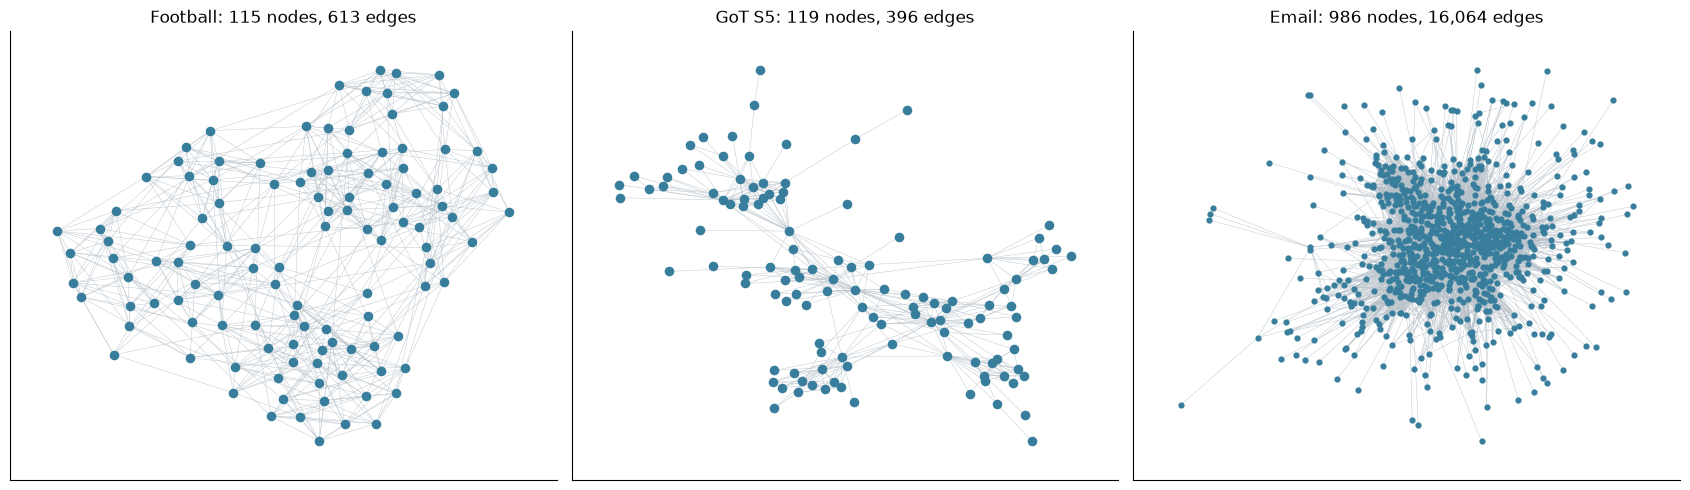

In [3]:
def connected_sample(factory, seed, attempts=1000):
    """Keep connected realizations, with bounded retries and a recorded seed."""
    for attempt in range(attempts):
        graph = factory(seed + attempt)
        if nx.is_connected(graph):
            graph.graph["generation_seed"] = seed + attempt
            graph.graph["attempts"] = attempt + 1
            return graph
    raise RuntimeError("No connected realization found within the retry limit")

def synthetic_graphs(n, seed, random_edges, radius, rewiring):
    factories = {
        "REG": lambda s: nx.watts_strogatz_graph(n, 4, 0, seed=s),
        "ER": lambda s: nx.gnm_random_graph(n, random_edges, seed=s),
        "RGG": lambda s: nx.random_geometric_graph(n, radius, seed=s),
        "BA": lambda s: nx.barabasi_albert_graph(n, 4, seed=s),
        "WS": lambda s: nx.watts_strogatz_graph(n, 4, rewiring, seed=s),
    }
    return {name: connected_sample(factory, seed) for name, factory in factories.items()}

def graph_summary(graph):
    return {"nodes": len(graph), "edges": graph.number_of_edges(),
            "components": nx.number_connected_components(graph),
            "mean_degree": np.mean([degree for _, degree in graph.degree()]),
            "mean_clustering": nx.average_clustering(graph, weight=None),
            "mean_closeness": np.mean(list(nx.closeness_centrality(graph).values()))}

def histogram_grid(values, xlabel, title, bins=15):
    columns = min(3, len(values))
    rows = math.ceil(len(values) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(5*columns, 3.3*rows), squeeze=False)
    for ax, (name, array) in zip(axes.flat, values.items()):
        ax.hist(list(array), bins=bins, color="#387e9c", edgecolor="white")
        ax.set(title=name, xlabel=xlabel, ylabel="Nodes")
    for ax in list(axes.flat)[len(values):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

with zipfile.ZipFile(fetch_data("football.zip")) as archive:
    member = next(name for name in archive.namelist() if name.endswith("football.gml"))
    football = nx.parse_gml(archive.read(member).decode("ascii").splitlines())
got = load_got(5)
with gzip.open(fetch_data("email-Eu-core.txt.gz"), "rt") as file:
    email_all = nx.read_edgelist(file, nodetype=int, data=False)
email_all.remove_edges_from(nx.selfloop_edges(email_all))
email = email_all.subgraph(max(nx.connected_components(email_all), key=len)).copy()
real_graphs = {"Football": football, "GoT S5": got, "Email": email}
graphs = synthetic_graphs(80, SEED, 300, .25, .3)
graphs.update(real_graphs)
summary = pd.DataFrame({name: graph_summary(graph) for name, graph in graphs.items()}).T
display(summary)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, graph) in zip(axes, real_graphs.items()):
    position = nx.spring_layout(graph, seed=SEED, weight=None)
    nx.draw_networkx(graph, position, ax=ax, with_labels=False, node_size=12 if len(graph)>500 else 35,
                     edge_color="#b7c1c9", width=.3, node_color="#387e9c")
    ax.set_title(f"{name}: {len(graph)} nodes, {graph.number_of_edges():,} edges")
plt.tight_layout()
plt.show()

## Topological fingerprints: degree, clustering, and closeness

We compare distributions and averages across all eight networks. Degree reveals unequal connectivity, clustering measures local triangle closure, and closeness measures short-path access to the rest of the graph. Each histogram shows the frequency of the measured values.

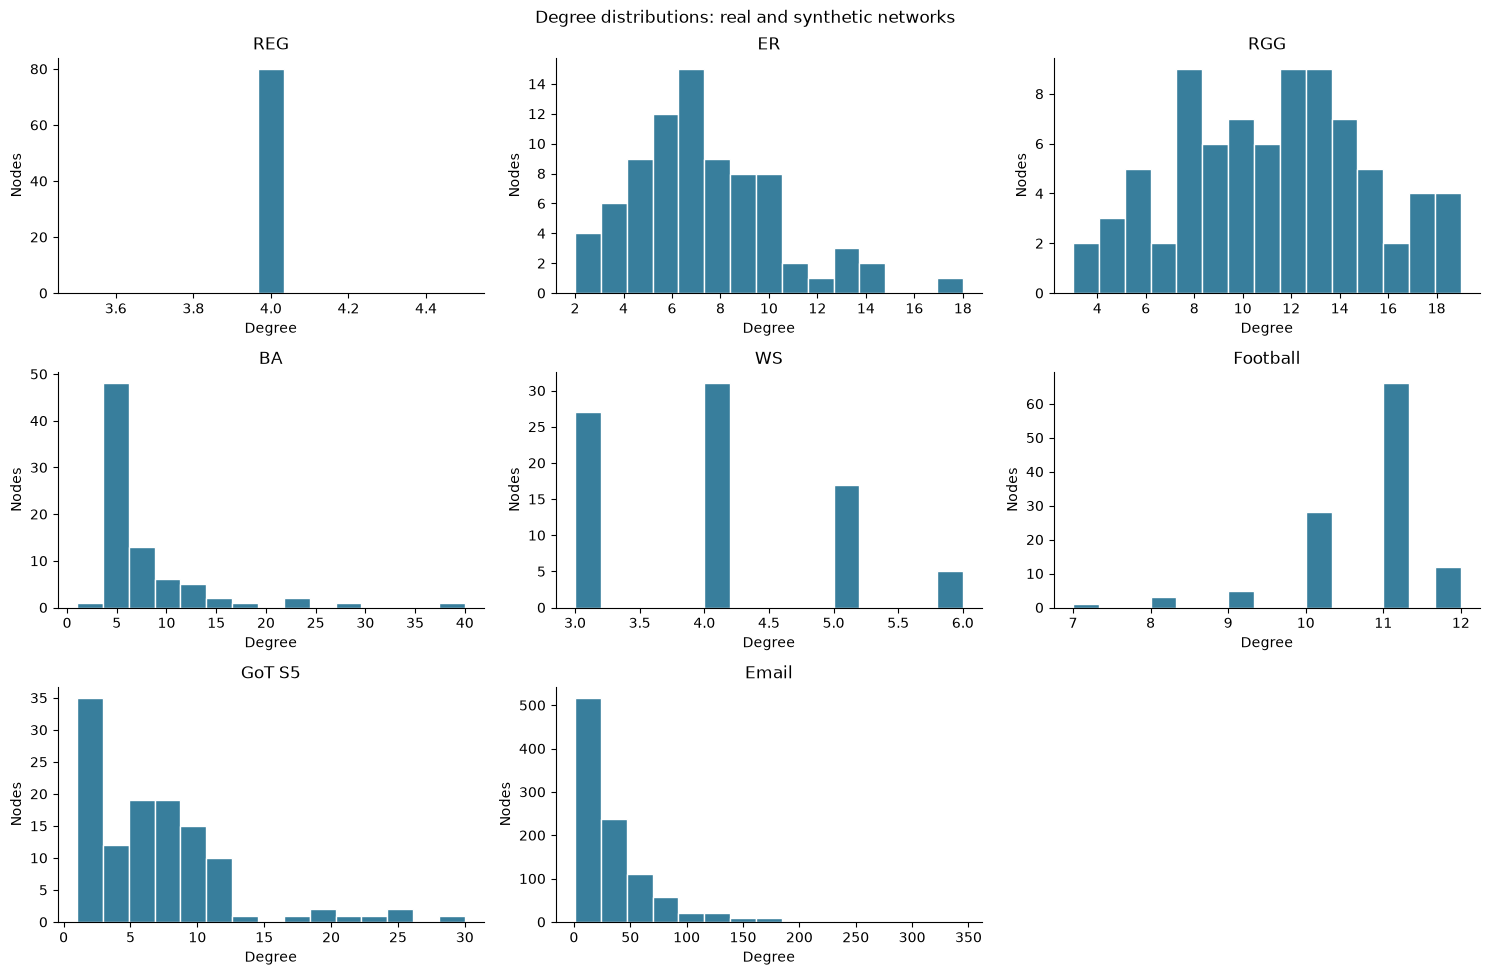

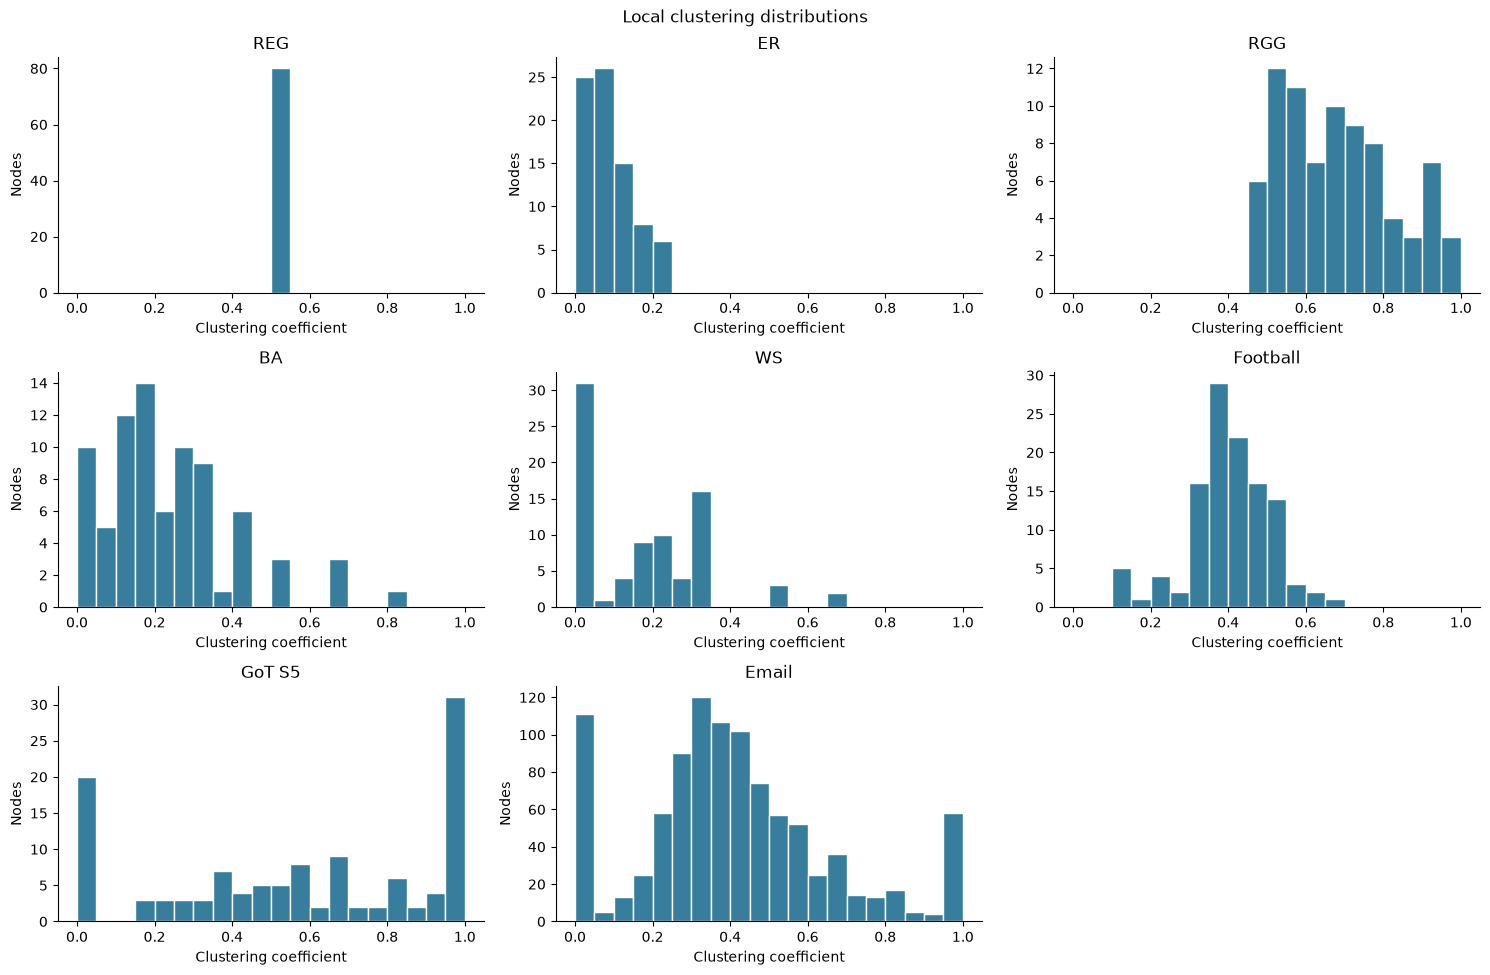

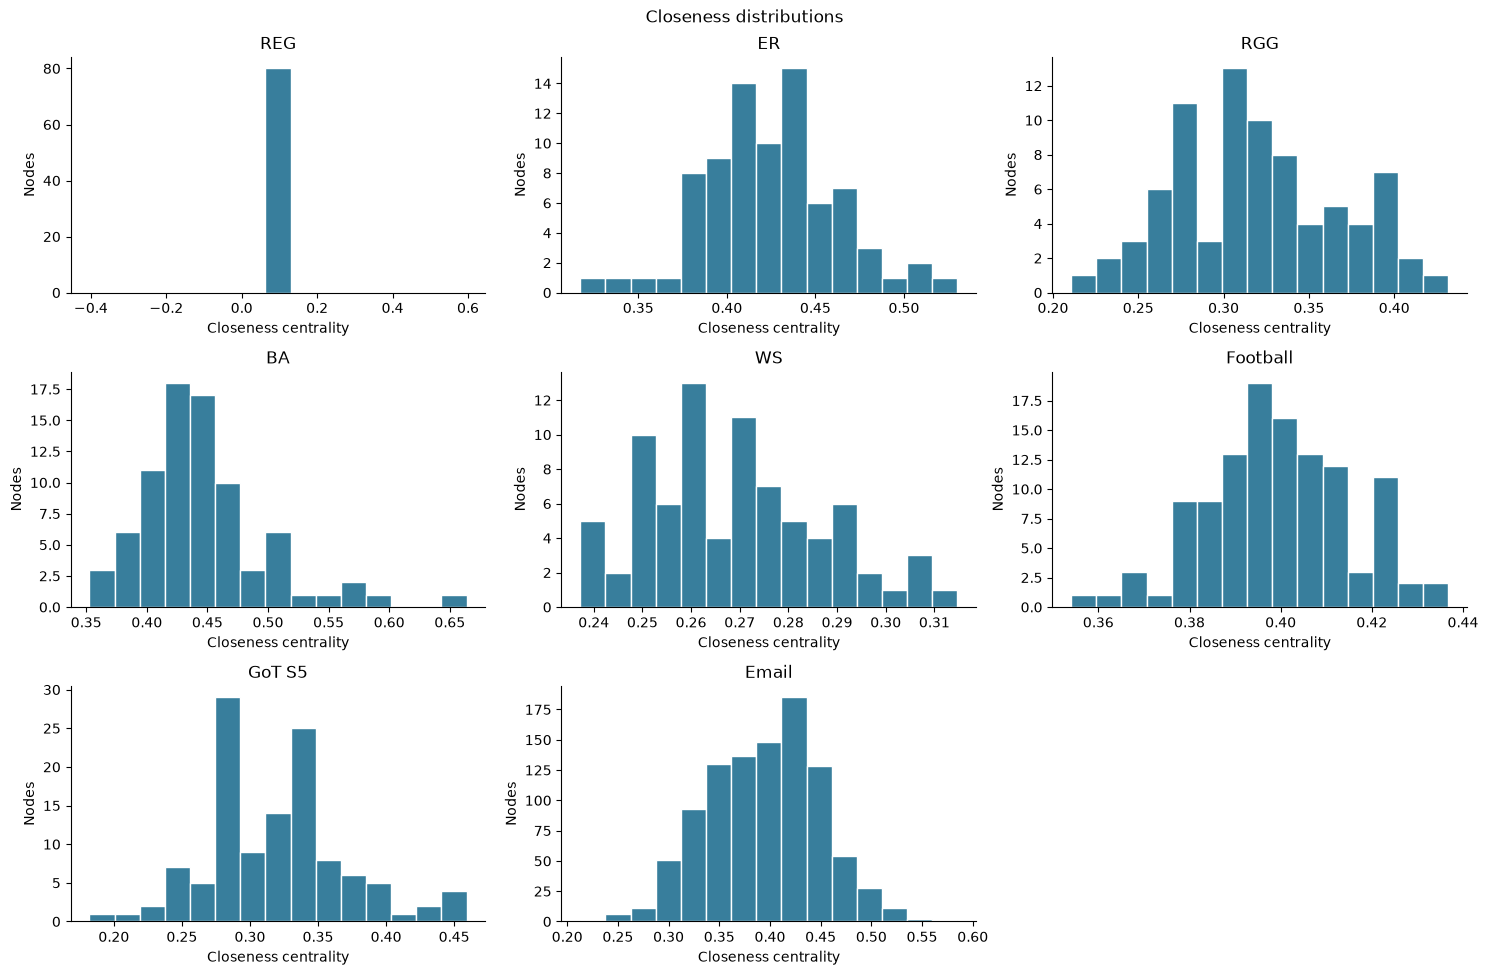

,mean_degree,mean_clustering,mean_closeness
REG,4.0000,0.5000,0.0963
ER,7.5000,0.0850,0.4242
RGG,11.2500,0.6826,0.3201
BA,7.6000,0.2292,0.4464
WS,4.0000,0.1671,0.2691
Football,10.6609,0.4032,0.3993
GoT S5,6.6555,0.5744,0.3191
Email,32.5842,0.4071,0.3945


In [4]:
degree_values = {name: [degree for _, degree in graph.degree()] for name, graph in graphs.items()}
clustering_values = {name: list(nx.clustering(graph, weight=None).values()) for name, graph in graphs.items()}
closeness_values = {name: list(nx.closeness_centrality(graph).values()) for name, graph in graphs.items()}
histogram_grid(degree_values, "Degree", "Degree distributions: real and synthetic networks")
histogram_grid(clustering_values, "Clustering coefficient", "Local clustering distributions", bins=np.linspace(0, 1, 21))
histogram_grid(closeness_values, "Closeness centrality", "Closeness distributions")
display(summary[["mean_degree", "mean_clustering", "mean_closeness"]])

### Reading the real–synthetic comparison

Football schedules constrain how many opponents each team has, producing a relatively narrow degree distribution. Conferences can still create substantial clustering. Character interactions and email contacts can be more unequal: a few characters or members have many links while most have fewer. Shared storylines or departments can create clustered neighborhoods.

No single reference model captures all these mechanisms. Similar mean closeness does not establish a common generative model, and high clustering alone does not prove geometric organization. Compare shapes and several measures together. The graphs also differ in size and density, so these comparisons characterize patterns rather than isolate a causal mechanism.

## Community methods and quality measures

**Girvan–Newman** repeatedly removes the edge with highest betweenness, recomputing betweenness after each removal. We use igraph's compiled exact edge-betweenness calculation and recompute it after every edge removal, stopping at the 50-group search limit. This avoids constructing the unused remainder of the hierarchy; ties may be resolved differently from NetworkX's implementation. The exact method remains edge-betweenness removal, not a sampled approximation.

**Spectral clustering** groups nodes using eigenvectors of the graph Laplacian. We explicitly pass adjacency as precomputed affinity and map labels back using the exact node list. **Greedy modularity** merges groups while improving modularity and chooses its own group count.

For Girvan–Newman and spectral clustering we search **two through 50 groups**, retaining both the partition with best modularity and the one with best performance. Each candidate is computed once and scored against both objectives. Greedy modularity is evaluated against the same scores.

Modularity compares internal edge concentration with a degree-based null model. Coverage is the fraction of edges inside groups. Performance counts internal edges and external non-edges as correct pair relationships; sparse networks can obtain high performance simply by separating many node pairs. A higher performance score is therefore not evidence of better department recovery.

In [5]:
import igraph as ig
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from threadpoolctl import threadpool_limits
MAX_COMMUNITIES = 50

def quality(graph, communities):
    assert nx.community.is_partition(graph, communities)
    membership = {u: i for i, group in enumerate(communities) for u in group}
    inside_edges = sum(membership[u] == membership[v] for u, v in graph.edges())
    possible_pairs = len(graph)*(len(graph)-1)//2
    inside_pairs = sum(len(group)*(len(group)-1)//2 for group in communities)
    outside_non_edges = possible_pairs-inside_pairs-(graph.number_of_edges()-inside_edges)
    return {"groups": len(communities),
            "modularity": nx.community.modularity(graph, communities, weight=None),
            "coverage": inside_edges/graph.number_of_edges(),
            "performance": (inside_edges+outside_non_edges)/possible_pairs}

def girvan_newman_partitions(graph, limit):
    nodes = sorted(graph, key=repr)
    index = {node: i for i, node in enumerate(nodes)}
    edges = sorted((min(index[u], index[v]), max(index[u], index[v])) for u, v in graph.edges())
    # Cache exact partitions keyed by graph content and engine version, never by a dataset name alone.
    identity = json.dumps({"nodes": nodes, "edges": edges, "limit": limit, "igraph": ig.__version__, "algorithm": "exact-prefix-v1"})
    key = hashlib.sha256(identity.encode()).hexdigest()
    path = CACHE / f"girvan-newman-{key}.json"
    if path.exists():
        saved = json.loads(path.read_text())
        return saved["partitions"], saved["compute_seconds"], True
    start = time.perf_counter()
    native = ig.Graph(n=len(nodes), edges=edges, directed=False)
    # Exact Girvan–Newman prefix: recompute after EVERY edge removal,
    # and stop at the search limit instead of splitting all nodes apart.
    partitions = []
    previous_count = len(native.connected_components())
    while previous_count < limit and native.ecount():
        betweenness = native.edge_betweenness(directed=False, weights=None)
        native.delete_edges(int(np.argmax(betweenness)))
        components = native.connected_components()
        if len(components) > previous_count:
            partitions.append([[nodes[i] for i in group] for group in components])
            previous_count = len(components)
            if len(graph) > 500 and previous_count % 10 == 0:
                print(f"  Girvan–Newman: {previous_count} groups", flush=True)
    seconds = time.perf_counter()-start
    payload = json.dumps({"partitions": partitions, "compute_seconds": seconds})
    with tempfile.NamedTemporaryFile(mode="w", dir=CACHE, delete=False) as temporary:
        temporary.write(payload)
        temporary_path = Path(temporary.name)
    temporary_path.replace(path)
    return partitions, seconds, False

partitions, result_rows, search_rows = {}, [], []
for name, graph in tqdm(graphs.items(), desc="Community benchmarks"):
    print(f"Analyzing {name} ({len(graph)} nodes, {graph.number_of_edges():,} edges)", flush=True)
    limit = min(MAX_COMMUNITIES, len(graph)-1)
    for method in ["Girvan–Newman", "Spectral", "Greedy modularity"]:
        start = time.perf_counter()
        cached, original_seconds = False, None
        if method == "Girvan–Newman":
            candidates, original_seconds, cached = girvan_newman_partitions(graph, limit)
        elif method == "Spectral":
            nodes = list(graph)
            adjacency = nx.to_numpy_array(graph, nodelist=nodes, weight=None)
            candidates = []
            with threadpool_limits(limits=2):
                for k in range(2, limit+1):
                    labels = SpectralClustering(n_clusters=k, affinity="precomputed", n_init=10,
                                                random_state=SEED, eigen_solver="arpack").fit_predict(adjacency)
                    candidates.append([{u for u, label in zip(nodes, labels) if label == group}
                                       for group in range(k)])
        else:
            candidates = [list(nx.community.greedy_modularity_communities(graph, weight=None))]
        scores = [quality(graph, candidate) for candidate in candidates]
        elapsed = time.perf_counter()-start
        for score in scores:
            search_rows.append({"network": name, "method": method, **score})
        objectives = ["modularity", "performance"] if method != "Greedy modularity" else ["modularity"]
        for objective in objectives:
            winner = max(range(len(candidates)), key=lambda i: scores[i][objective])
            partitions[(name, method, objective)] = candidates[winner]
            result_rows.append({"network": name, "method": method, "selected_by": objective,
                **scores[winner], "run_seconds": elapsed, "cached_GN": cached,
                "GN_compute_seconds": original_seconds})
results = pd.DataFrame(result_rows)
search_results = pd.DataFrame(search_rows)
display(results.set_index(["network", "method", "selected_by"]))

Community benchmarks: 100%|##########| 8/8 [00:29<00:00,  3.65s/it]


Analyzing REG (80 nodes, 160 edges)
Analyzing ER (80 nodes, 300 edges)
Analyzing RGG (80 nodes, 450 edges)
Analyzing BA (80 nodes, 304 edges)
Analyzing WS (80 nodes, 160 edges)
Analyzing Football (115 nodes, 613 edges)
Analyzing GoT S5 (119 nodes, 396 edges)
Analyzing Email (986 nodes, 16,064 edges)


groups  modularity  coverage  \
network  method            selected_by                                 
REG      Girvan–Newman     modularity        8      0.7250    0.8500   
                           performance      16      0.6375    0.7000   
         Spectral          modularity        7      0.7250    0.8688   
                           performance      22      0.5409    0.5875   
         Greedy modularity modularity        4      0.6731    0.9250   
ER       Girvan–Newman     modularity       24      0.2111    0.3167   
                           performance      34      0.1681    0.2133   
         Spectral          modularity        8      0.2708    0.4733   
                           performance      33      0.1441    0.1967   
         Greedy modularity modularity        4      0.2836    0.5500   
RGG      Girvan–Newman     modularity        5      0.5970    0.8889   
                           performance      22      0.4894    0.6467   
         Spectral          modularity        6      0.6022    0.8511   
                           performance      10      0.4934    0.6222   
         Greedy modularity modularity        4      0.5854    0.9044   
BA       Girvan–Newman     modularity       30      0.1364    0.4211   
                           performance      43      0.1157    0.1875   
         Spectral          modularity        4      0.2680    0.5658   
                           performance      30      0.1092    0.2270   
         Greedy modularity modularity        5      0.2700    0.4836   
WS       Girvan–Newman     modularity        8      0.5741    0.7188   
                           performance      31      0.4019    0.4437   
         Spectral          modularity        7      0.5558    0.7125   
                           performance      26      0.4136    0.4562   
         Greedy modularity modularity        8      0.5632    0.6937   
Football Girvan–Newman     modularity       10      0.5996    0.7096   
                           performance      17      0.5668    0.6460   
         Spectral          modularity       11      0.6022    0.6982   
                           performance      17      0.5445    0.6183   
         Greedy modularity modularity        6      0.5564    0.7390   
GoT S5   Girvan–Newman     modularity        8      0.6681    0.8535   
                           performance      50      0.4839    0.6010   
         Spectral          modularity        7      0.6654    0.8535   
                           performance      34      0.3453    0.4495   
         Greedy modularity modularity        5      0.6605    0.8788   
Email    Girvan–Newman     modularity        2      0.0006    0.9995   
                           performance      50      0.0006    0.9965   
         Spectral          modularity       11      0.3755    0.6525   
                           performance      29      0.2988    0.6175   
         Greedy modularity modularity        8      0.3471    0.6848   

                                        performance  run_seconds  cached_GN  \
network  method            selected_by                                        
REG      Girvan–Newman     modularity        0.9215       0.0188       True   
                           performance       0.9696       0.0188       True   
         Spectral          modularity        0.9044       1.6610      False   
                           performance       0.9744       1.6610      False   
         Greedy modularity modularity        0.8006       0.0105      False   
ER       Girvan–Newman     modularity        0.8949       0.0329       True   
                           performance       0.9215       0.0329       True   
         Spectral          modularity        0.8247       2.2992      False   
                           performance       0.9149       2.2992      False   
         Greedy modularity modularity        0.7592       0.0330      False   
RGG      Girvan–Newman     modularity        0.8639       0.2717   

## Visualizing the search and all selected partitions

The quality curves show how the chosen objective changes as the number of groups increases. Each network has a five-panel comparison: Girvan–Newman by modularity and by performance, spectral clustering by both objectives, and greedy modularity.

A single seeded layout per network keeps positions fixed across panels. Community colors are categorical identifiers inside a panel; the same color across different methods need not represent the same group. Email is dense, so node color is more informative than individual edges at this scale.

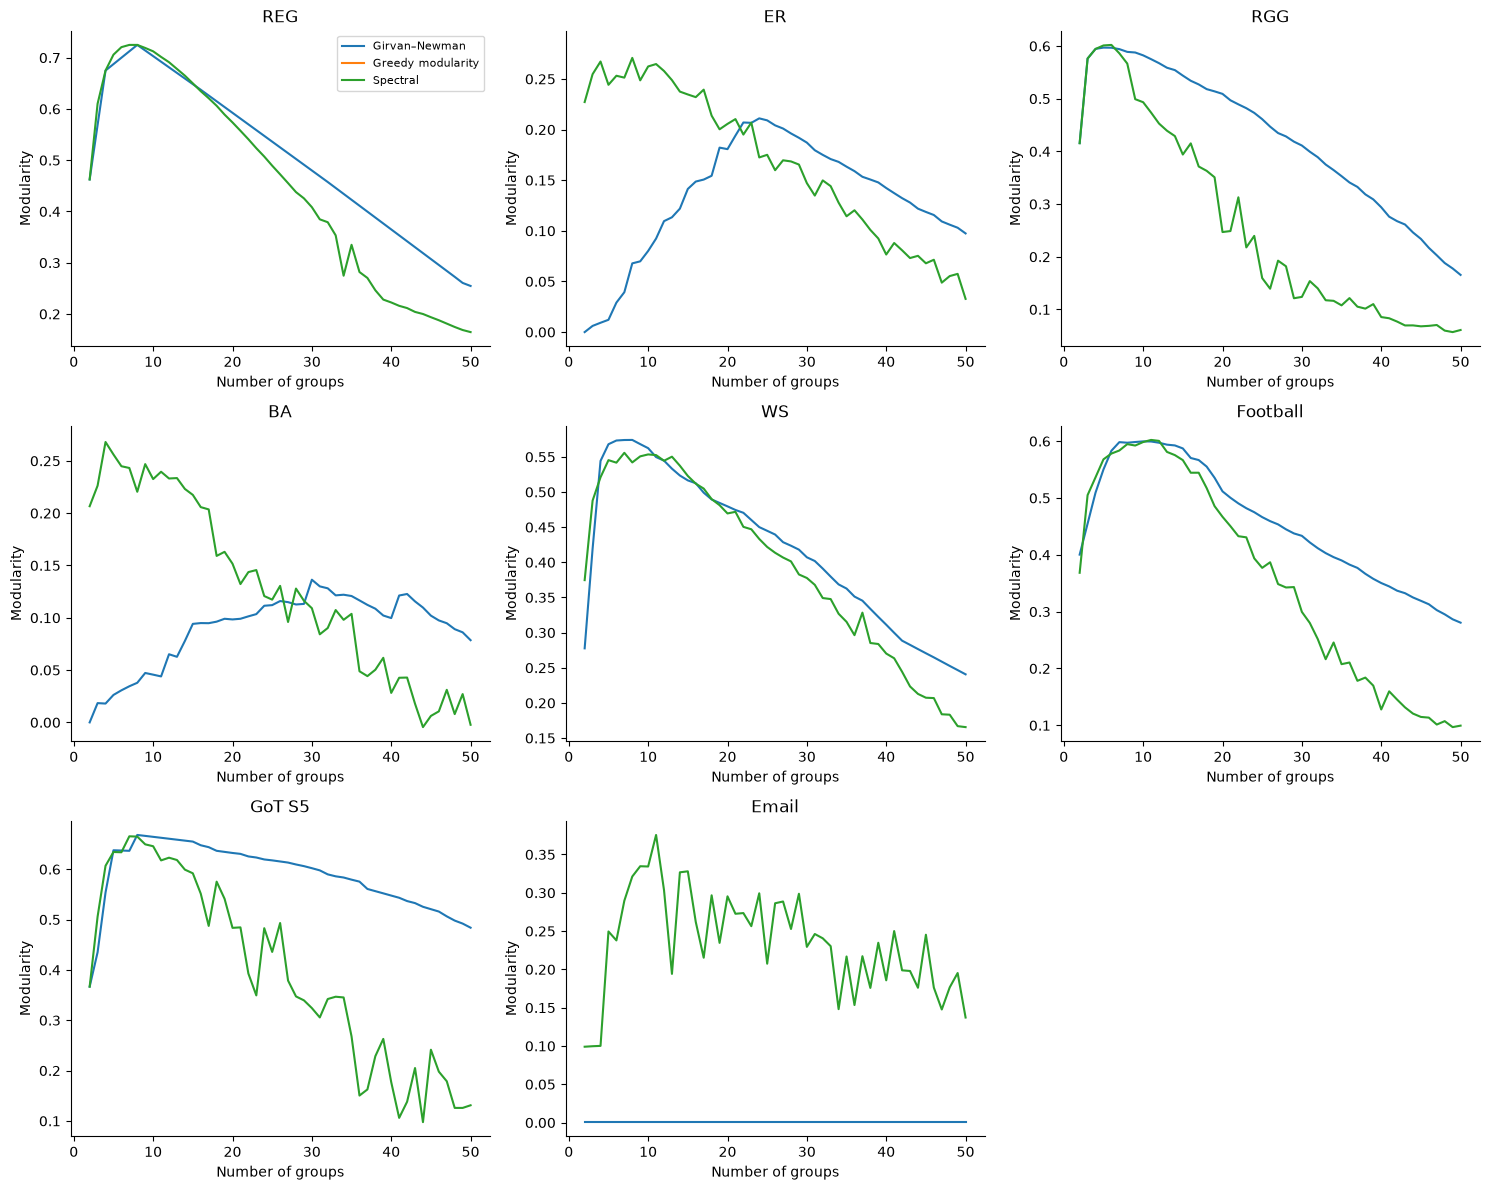

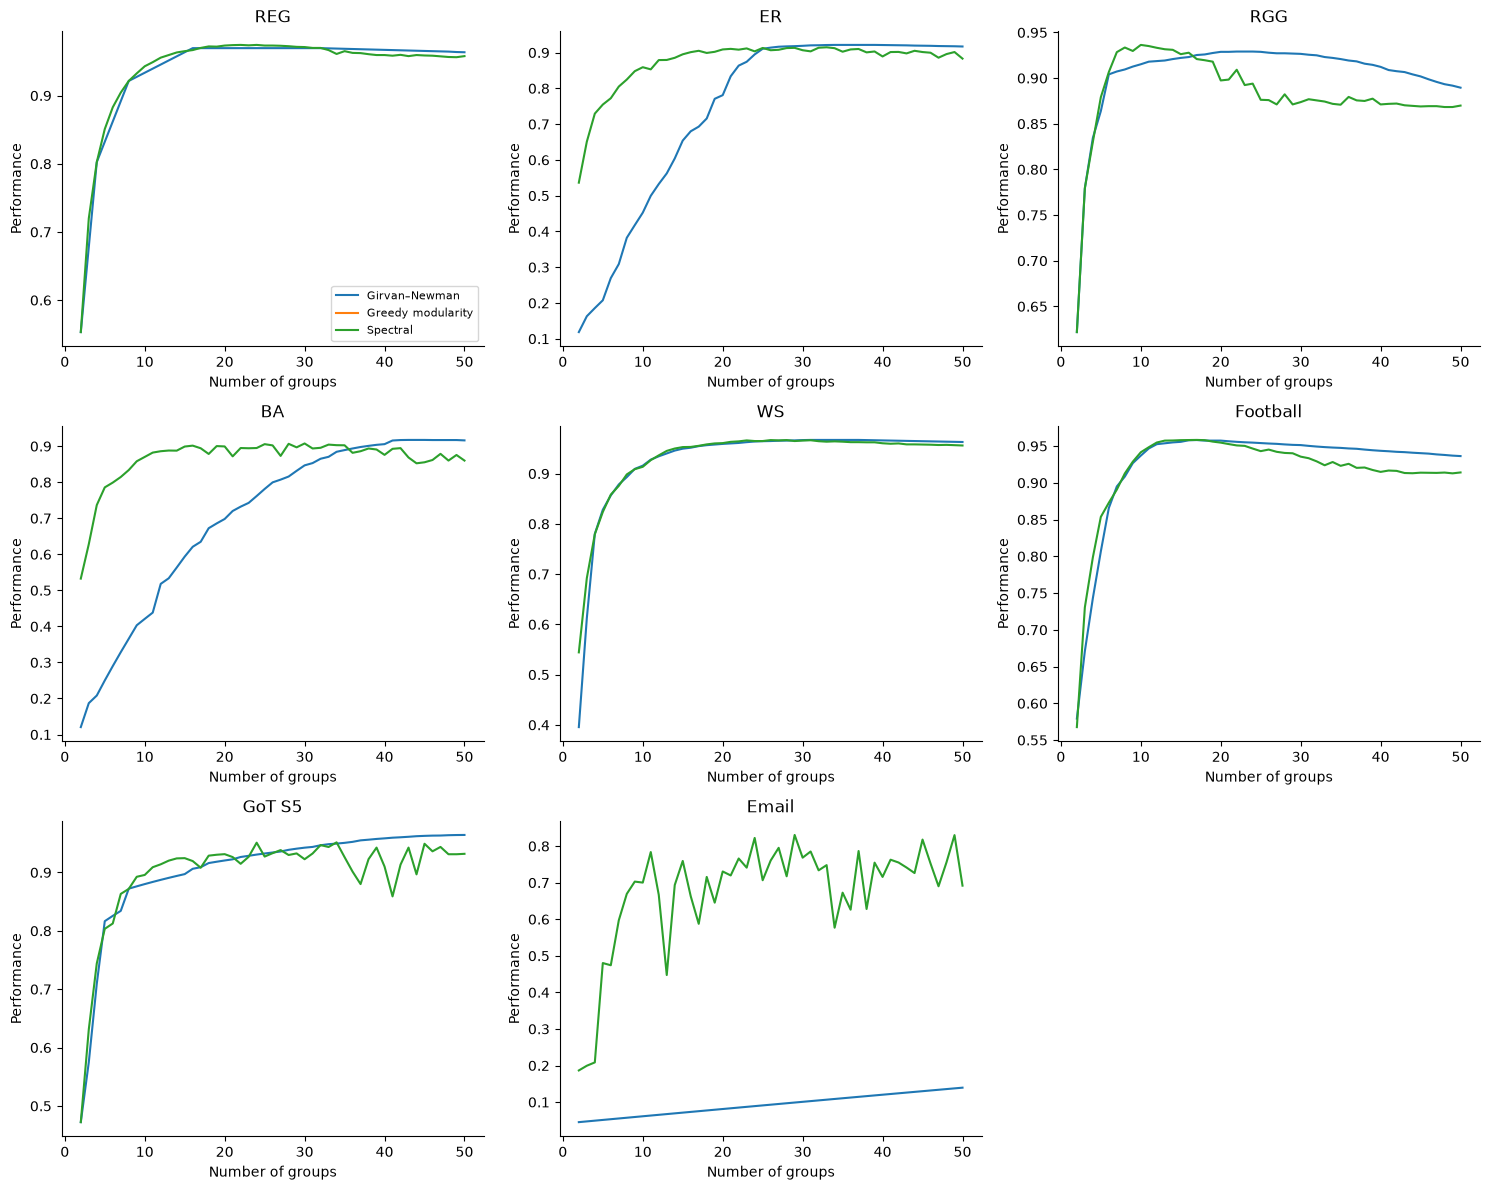

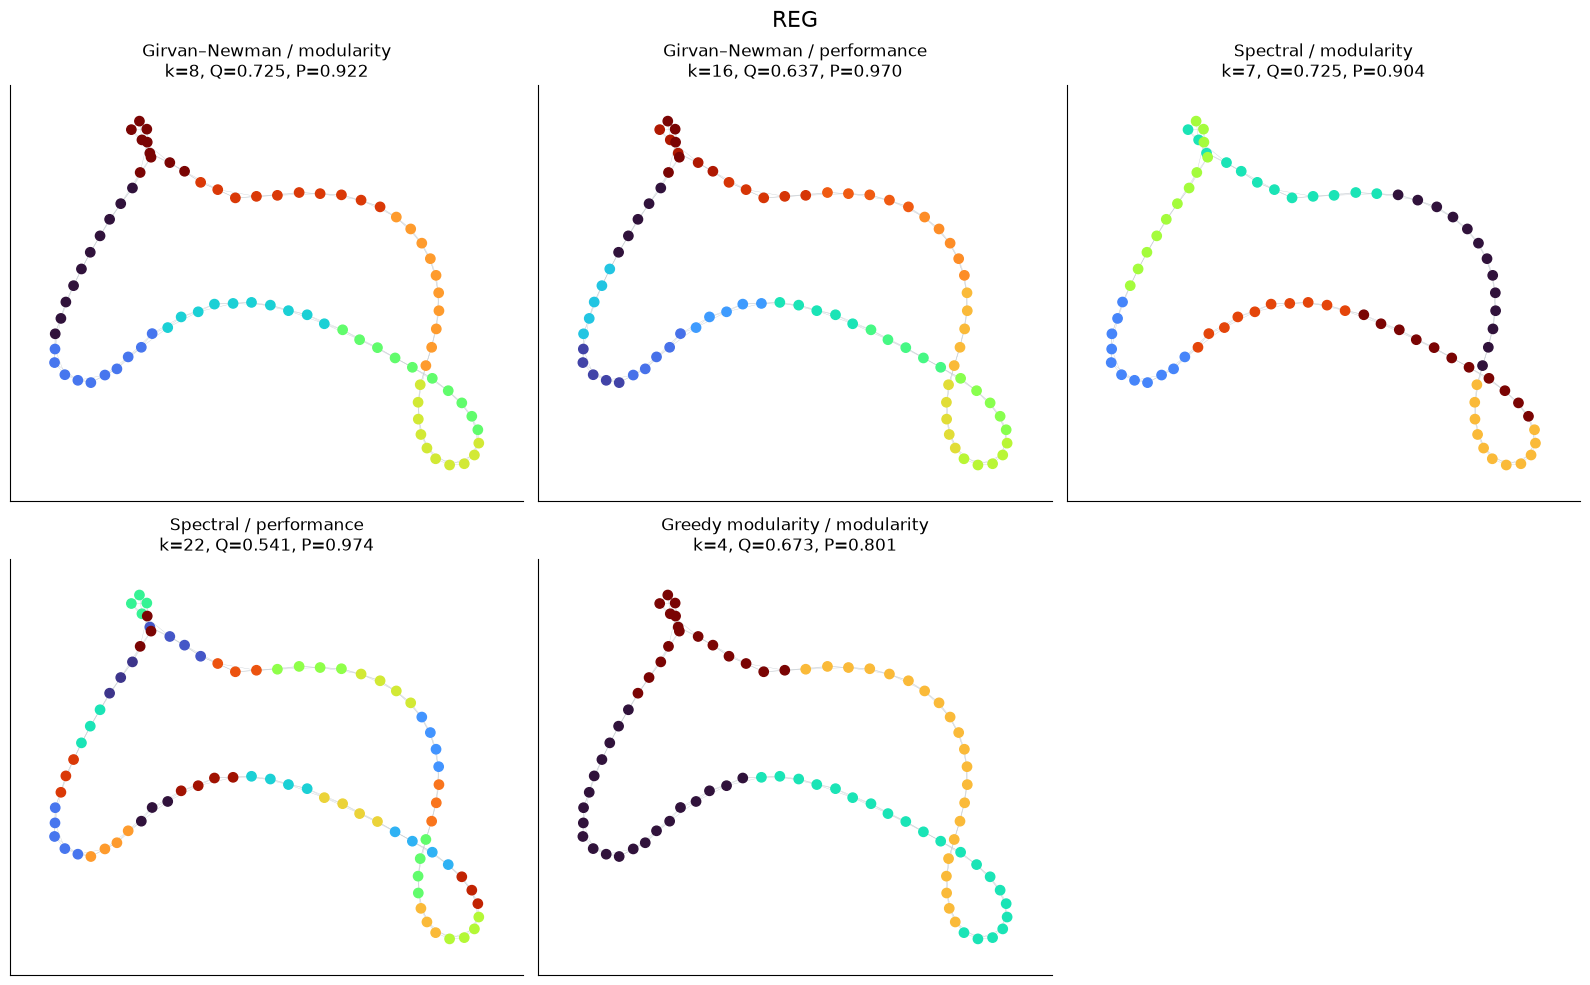

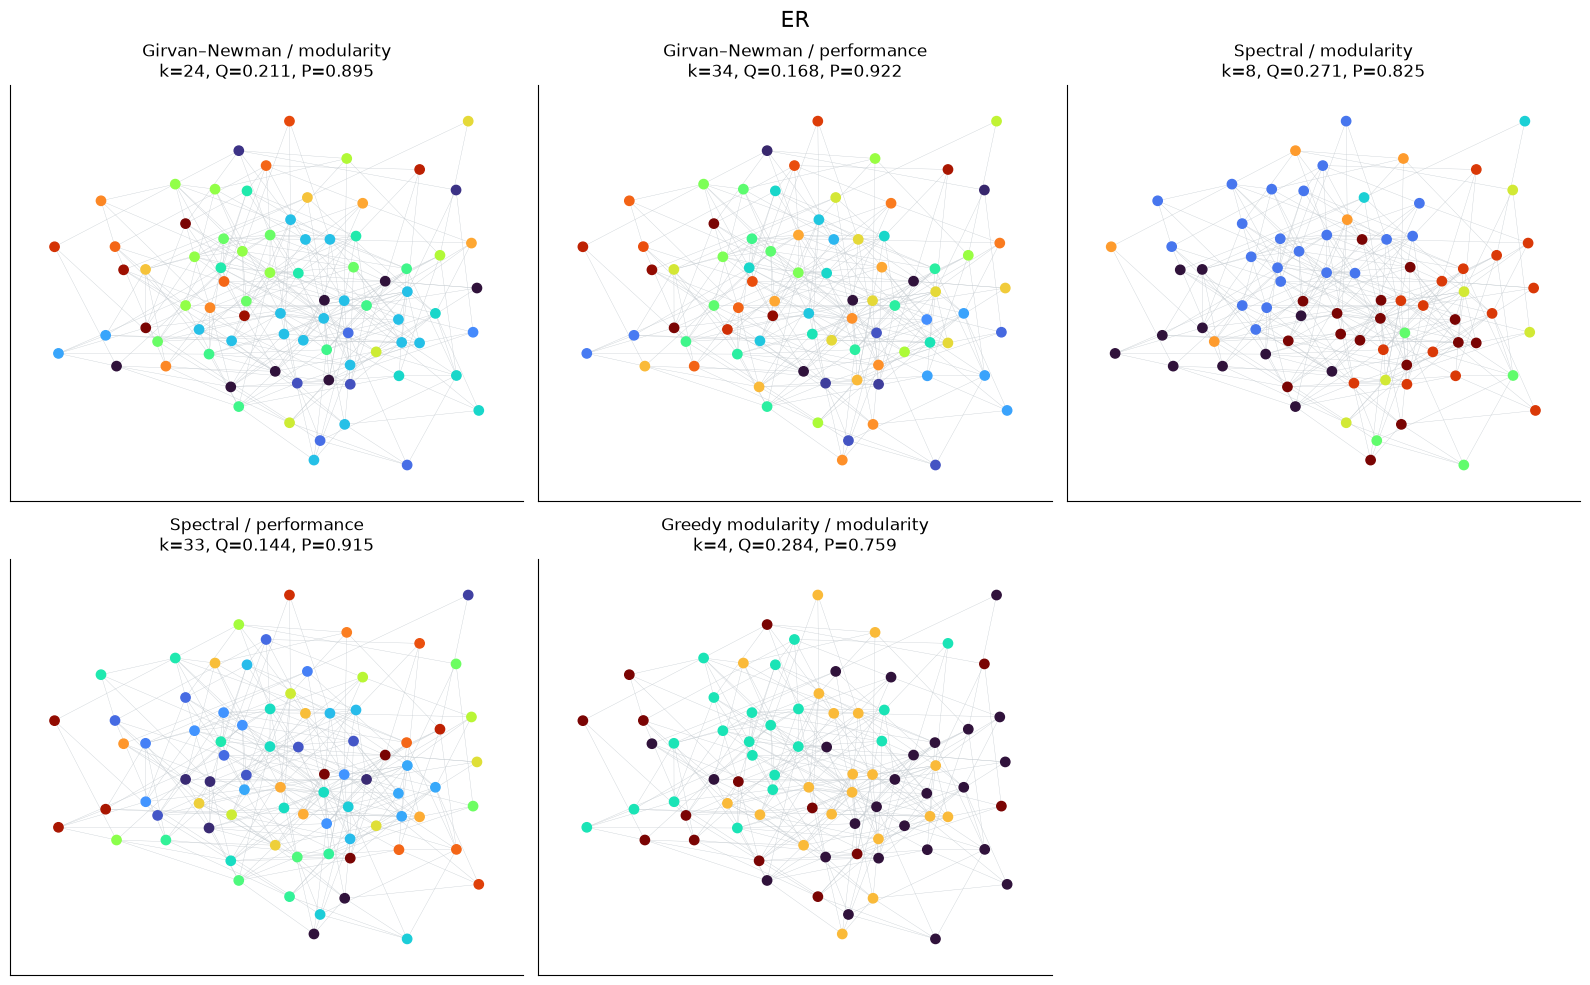

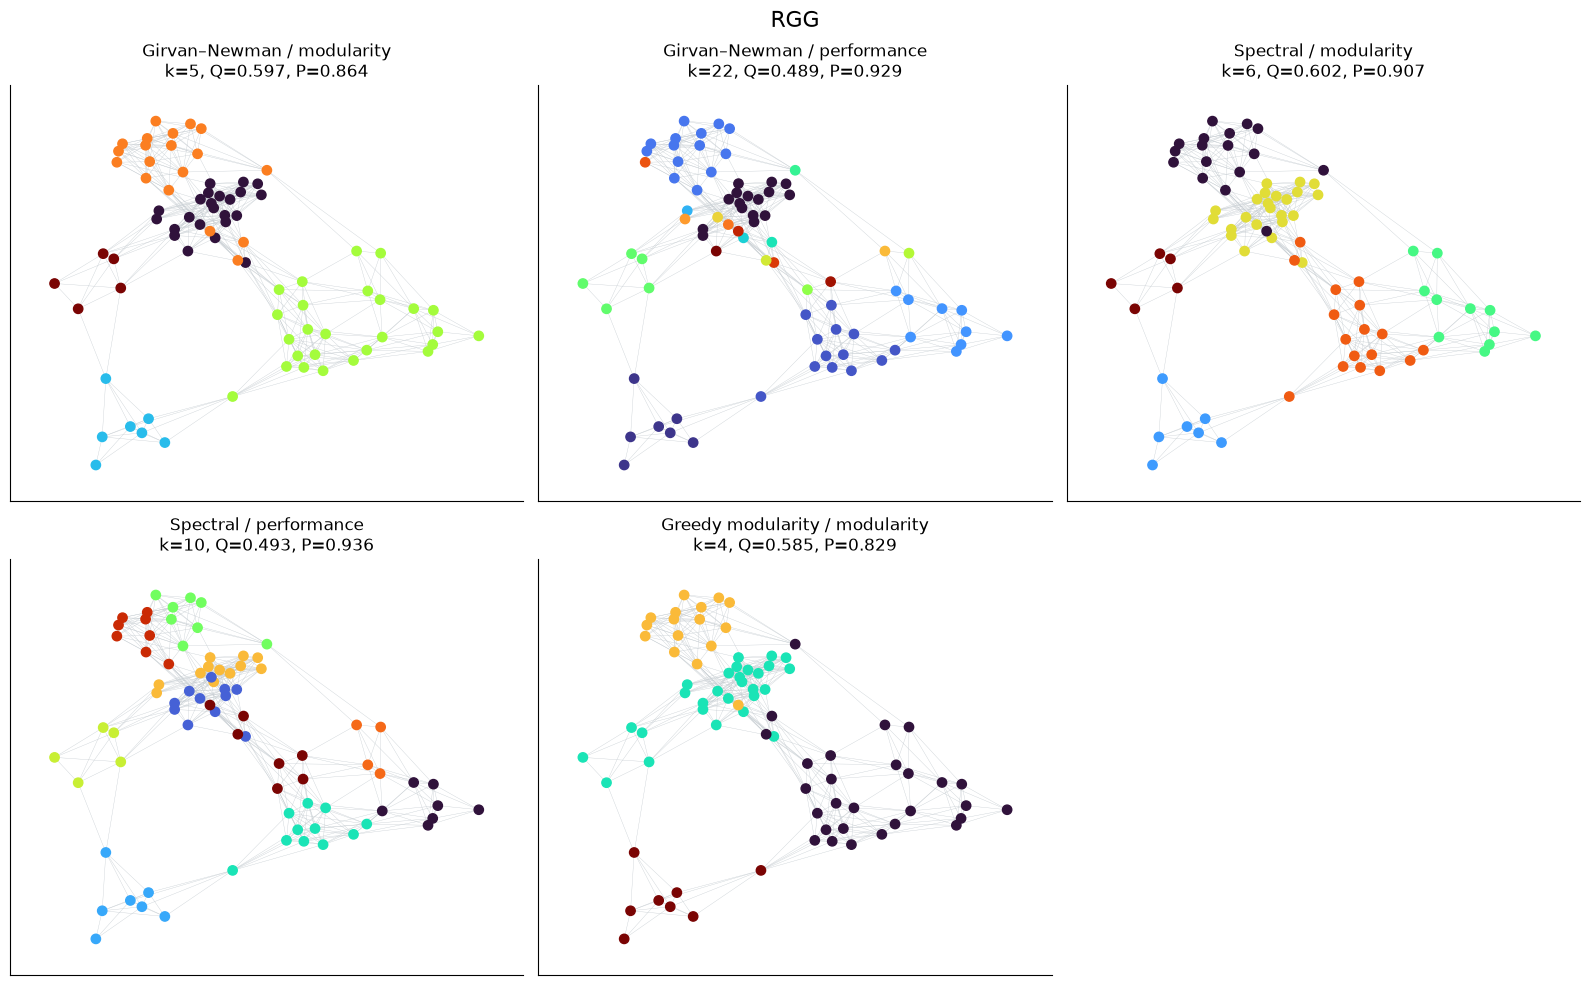

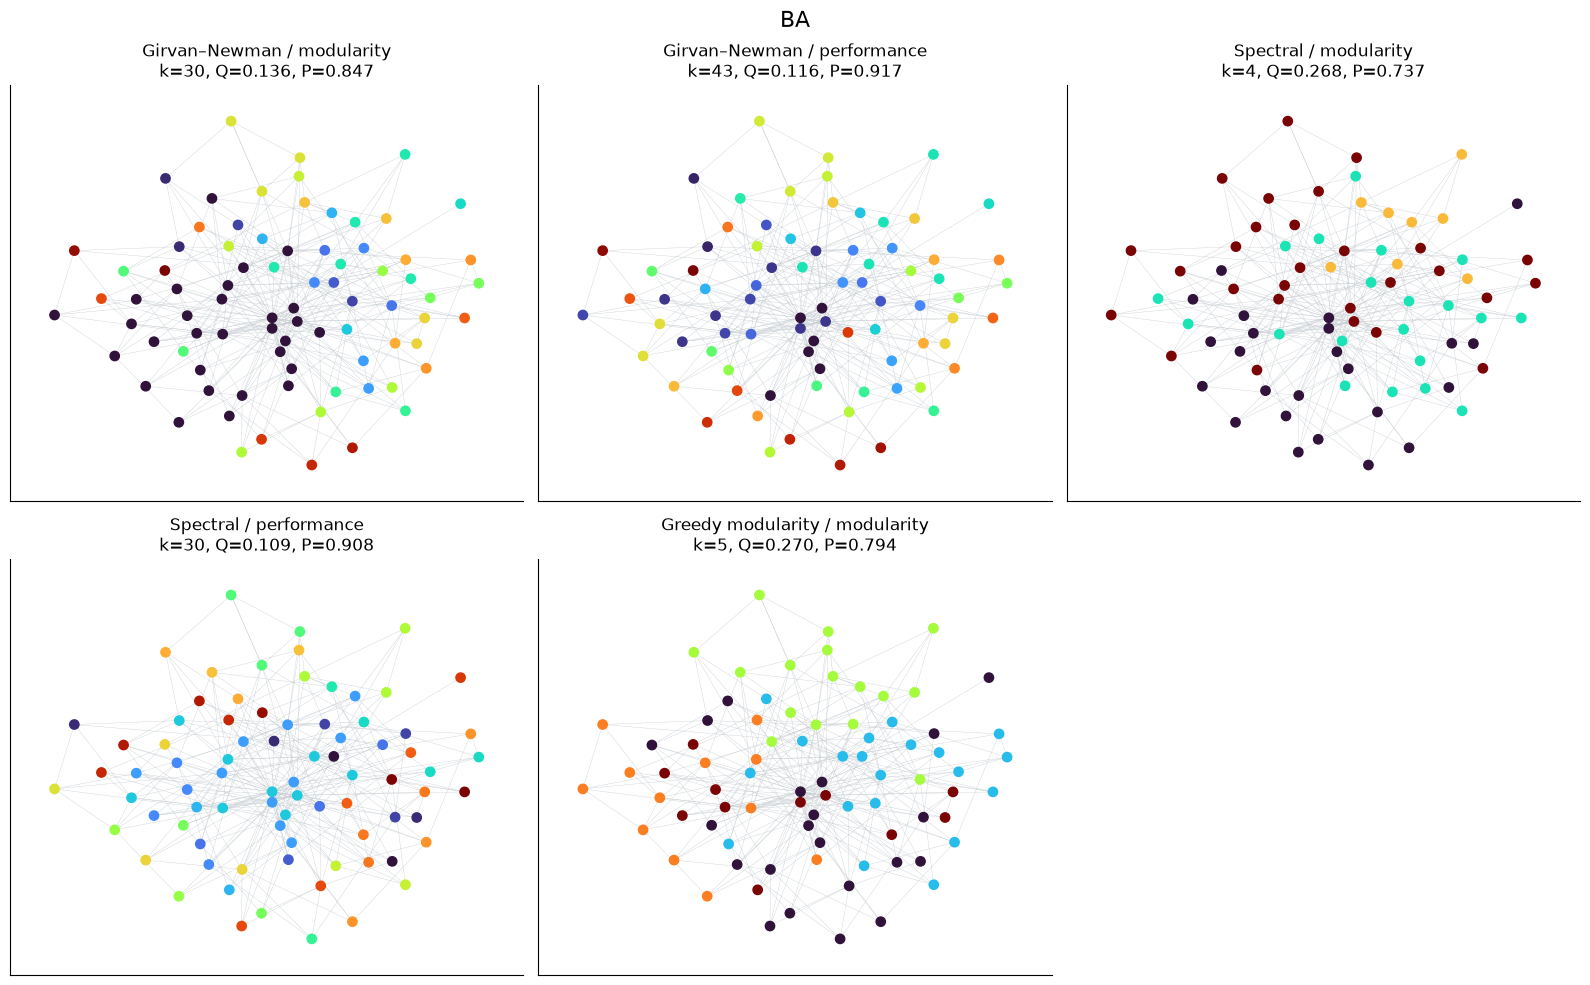

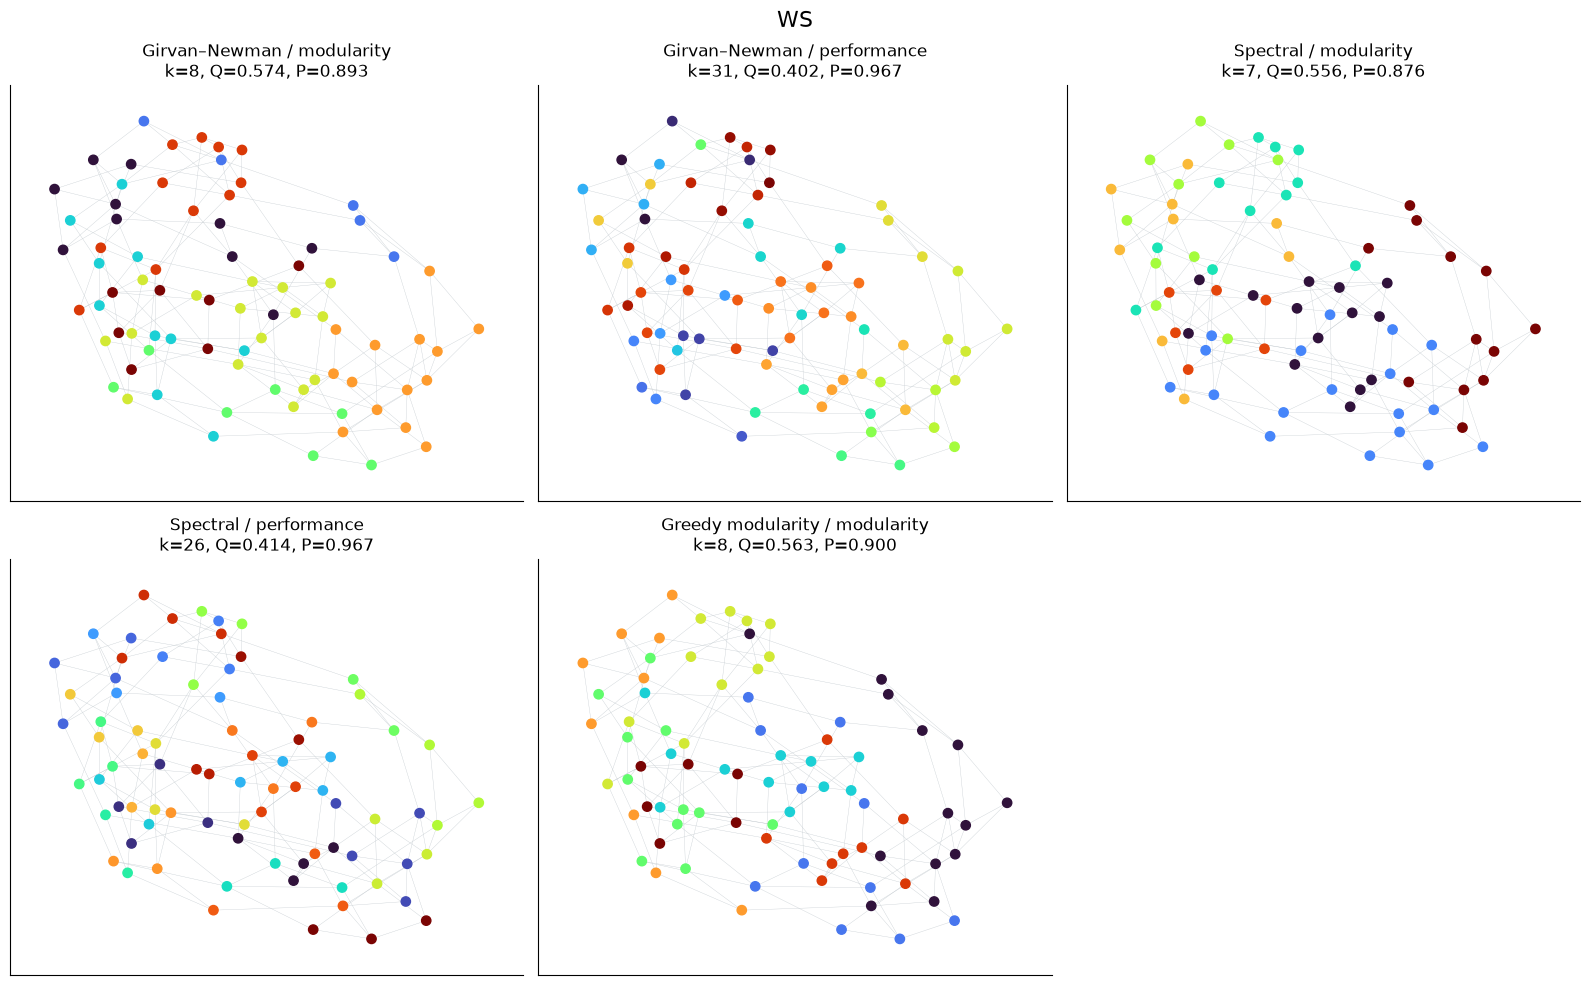

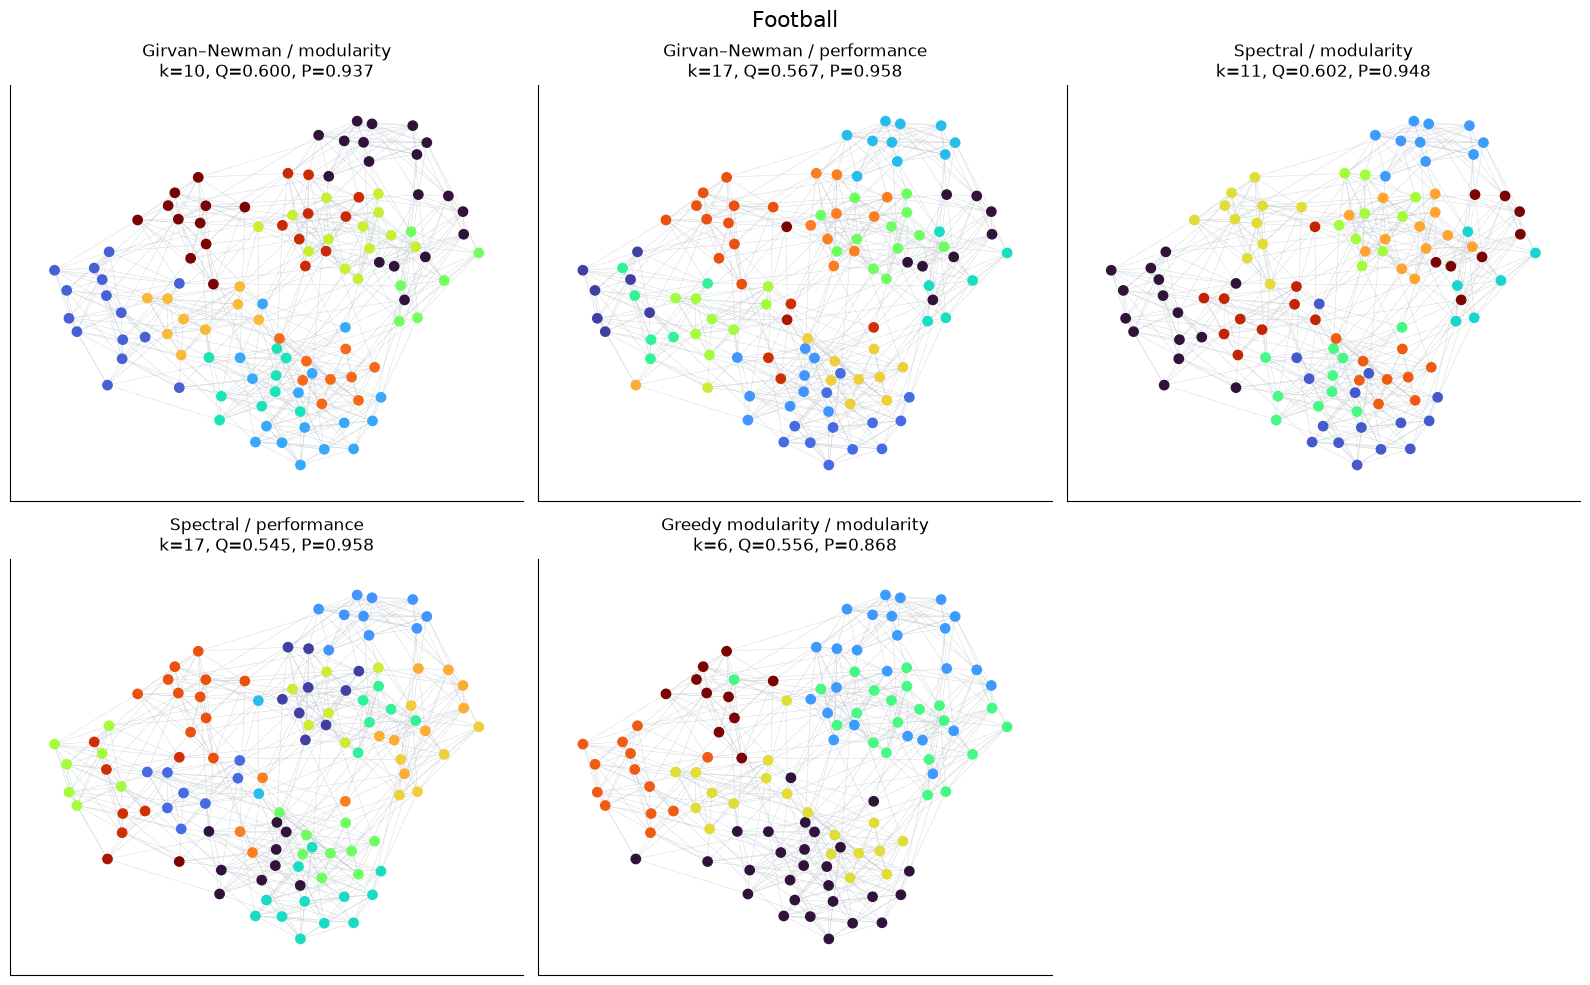

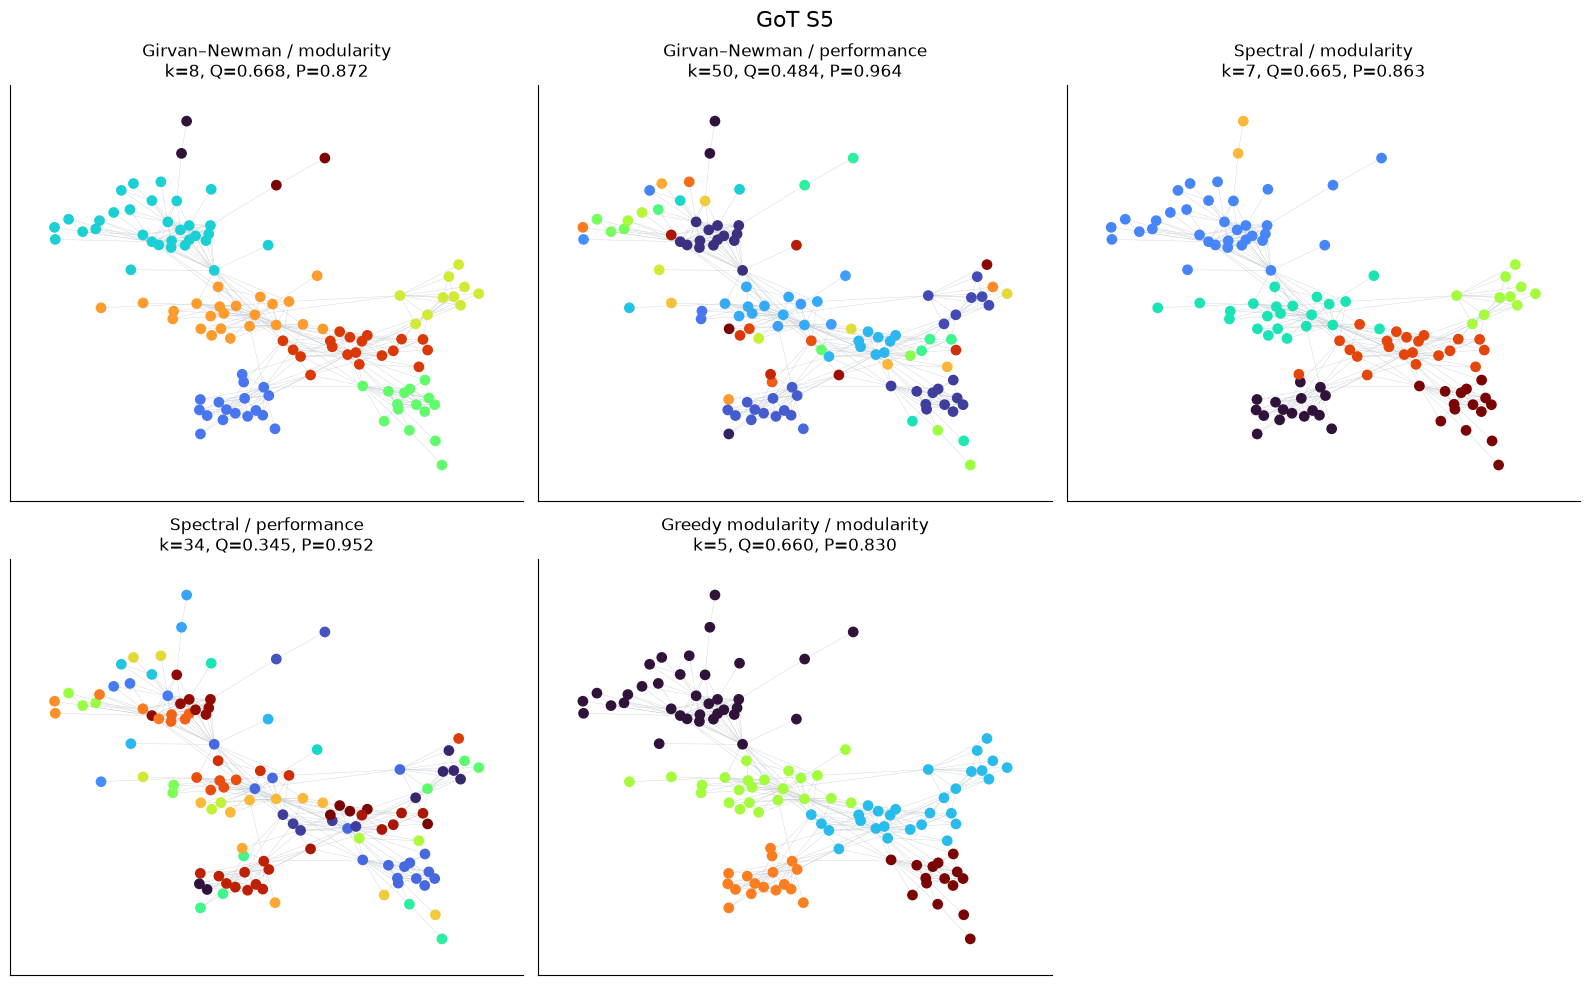

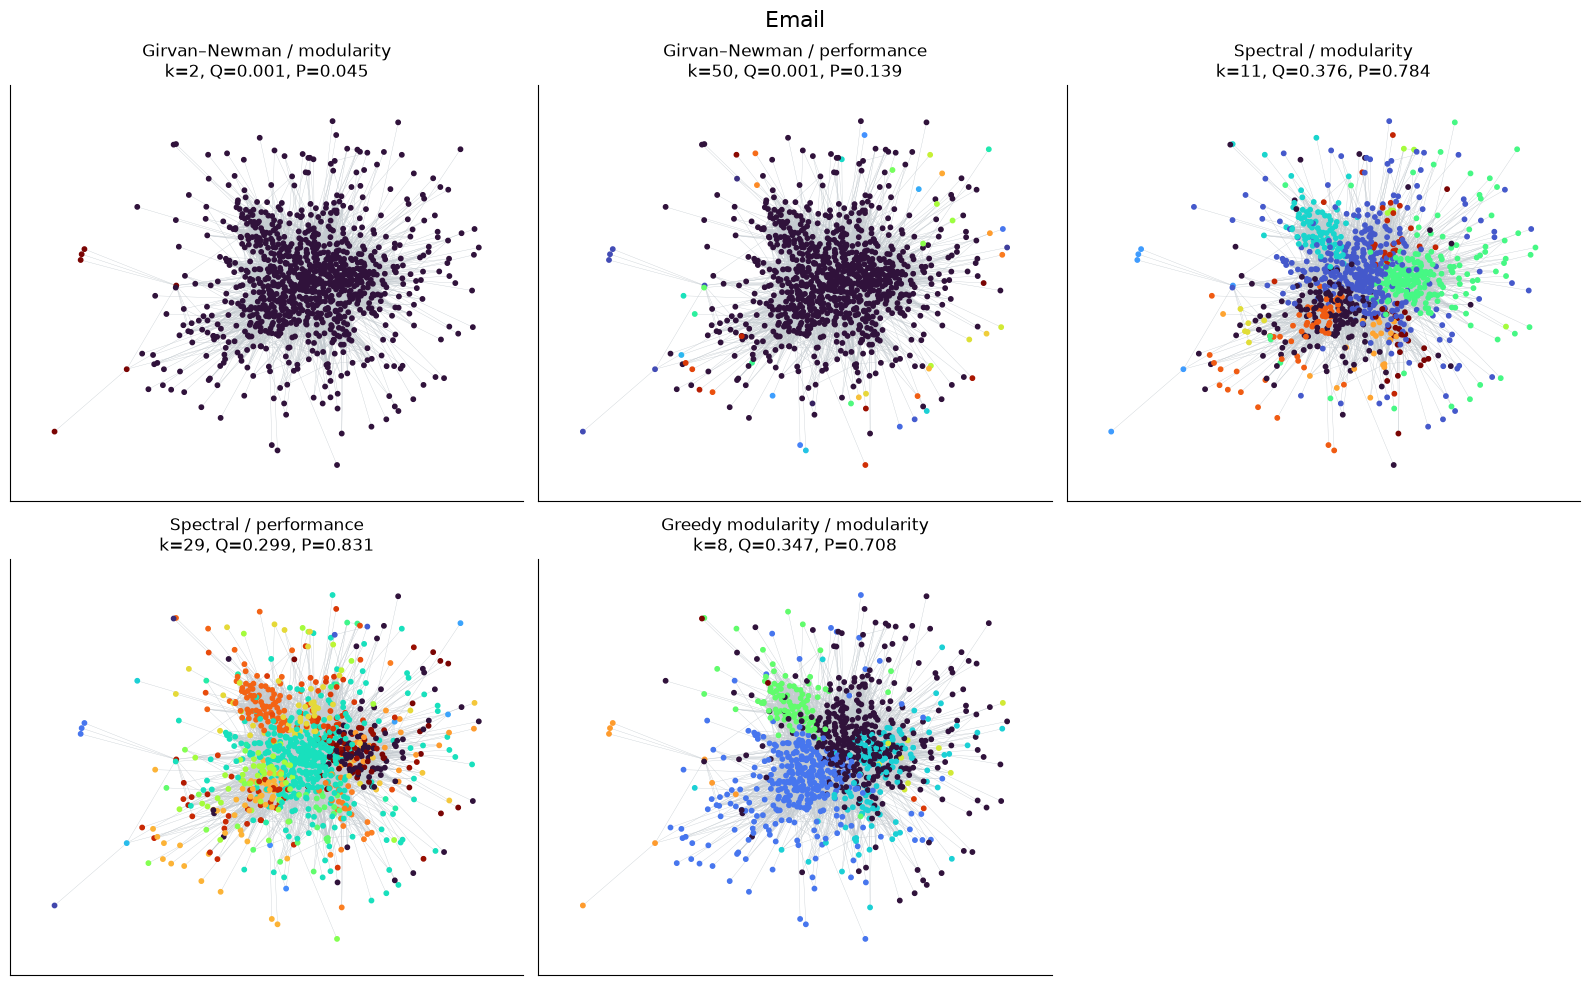

In [6]:
for objective in ["modularity", "performance"]:
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    for ax, name in zip(axes.flat, graphs):
        for method, group in search_results[search_results.network.eq(name)].groupby("method"):
            ax.plot(group.groups, group[objective], label=method)
        ax.set(title=name, xlabel="Number of groups", ylabel=objective.capitalize())
    for ax in list(axes.flat)[len(graphs):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

layouts = {name: nx.spring_layout(graph, seed=SEED, weight=None) for name, graph in graphs.items()}
for name, graph in graphs.items():
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    chosen = [(key, groups) for key, groups in partitions.items() if key[0] == name]
    for ax, ((_, method, objective), groups) in zip(axes.flat, chosen):
        membership = {node: i for i, group in enumerate(groups) for node in group}
        nx.draw_networkx(graph, layouts[name], ax=ax, with_labels=False,
                         node_color=[membership[u] for u in graph], cmap="turbo",
                         vmin=0, vmax=max(1, len(groups)-1),
                         node_size=10 if len(graph)>500 else 45,
                         edge_color="#c4cbd0", width=.25)
        score = quality(graph, groups)
        ax.set_title(f"{method} / {objective}\nk={len(groups)}, Q={score['modularity']:.3f}, P={score['performance']:.3f}")
    axes.flat[-1].set_visible(False)
    fig.suptitle(name, fontsize=16)
    plt.tight_layout()
    plt.show()

### What the partitions reveal in these networks

**REG and RGG:** partitions follow ring segments or spatial neighborhoods. Their high modularity shows that local construction alone can create strong structural groups. **WS:** residual lattice neighborhoods remain visible after rewiring, while shortcuts connect them. **ER and BA:** the algorithms still return partitions, but their weaker modularity relative to the locally organized references cautions against treating every discovered group as a planted community.

**Football:** dense groups are consistent with conference-based schedules; different objectives split those groups at different scales. **GoT S5:** communities separate clusters of interacting characters and can be read as candidate narrative groups, rather than proof of an intended storyline label.

**Email:** the first 50 Girvan–Newman partitions largely peel small groups away from a giant component. Its near-zero modularity in this bounded search does not show that the email network lacks communities: spectral clustering and greedy modularity find substantially stronger partitions on the same graph. The department comparison below tests how closely any of those structural groups match the organization chart.

### Interpreting algorithm differences

Modularity and performance can select very different group counts from the same hierarchy. Performance often favors smaller groups in sparse graphs because between-group non-edges dominate the pair count. A high-modularity partition of a regular lattice can divide it into contiguous segments even though there are no planted social groups. A method returning groups is not, by itself, evidence of a meaningful social division.

The search is bounded at 50 groups. A best score at that boundary means the unconstrained optimum has not been established. Girvan–Newman timing includes one hierarchy prefix reused for both objectives; its first-run compute time is reported separately when the hierarchy is loaded from cache. Spectral timing includes every fitted candidate, while greedy timing covers one automatic partition.

## Comparing the email partitions with recorded departments

Department labels are joined by **node ID** and restricted to members of the analyzed connected component. This keeps the membership labels aligned with the graph used by every algorithm.

We evaluate the department partition with modularity and performance, then compare each inferred partition using adjusted Rand index (ARI) and normalized mutual information (NMI). ARI corrects pair agreement for chance; one is perfect agreement and values near zero indicate chance-level agreement. NMI measures shared information on a zero-to-one scale. Both ignore arbitrary community IDs.

groups  modularity  coverage  \
method               selected_by                                     
Recorded departments observed labels      42      0.2880    0.3357   
Girvan–Newman        modularity            2      0.0006    0.9995   
                     performance          50      0.0006    0.9965   
Spectral             modularity           11      0.3755    0.6525   
                     performance          29      0.2988    0.6175   
Greedy modularity    modularity            8      0.3471    0.6848   

                                      performance     ARI     NMI  
method               selected_by                                   
Recorded departments observed labels       0.9428  1.0000  1.0000  
Girvan–Newman        modularity            0.0452 -0.0003  0.0102  
                     performance           0.1394  0.0006  0.0983  
Spectral             modularity            0.7837  0.2069  0.5464  
                     performance           0.8305  0.1971  0.6058  
Greedy modularity    modularity            0.7079  0.1535  0.4273

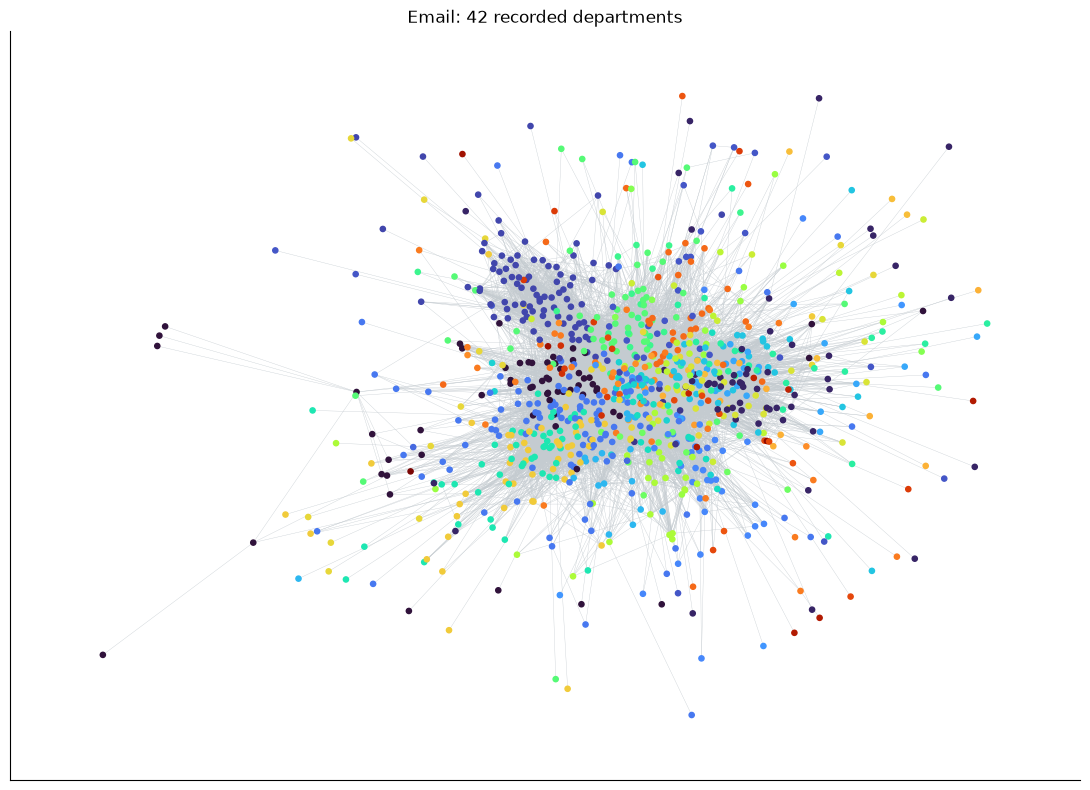

For the email graph, the highest observed modularity is **0.376** from **Spectral**, selected by modularity. The strongest department agreement is **ARI=0.207** from **Spectral**, selected by modularity. These are separate objectives: communication groups need not reproduce the organization chart.

In [7]:
with gzip.open(fetch_data("email-Eu-core-department-labels.txt.gz"), "rt") as file:
    department_by_node = {int(node): int(department) for node, department in (line.split() for line in file if line.strip())}
assert set(email).issubset(department_by_node)
departments = {}
for node in email:
    departments.setdefault(department_by_node[node], set()).add(node)
department_partition = list(departments.values())
assert nx.community.is_partition(email, department_partition)
truth_score = quality(email, department_partition)
nodes = list(email)
truth = [department_by_node[node] for node in nodes]
comparison_rows = [{"method": "Recorded departments", "selected_by": "observed labels",
                    **truth_score, "ARI": 1.0, "NMI": 1.0}]
for (name, method, objective), groups in partitions.items():
    if name == "Email":
        membership = {u: i for i, group in enumerate(groups) for u in group}
        labels = [membership[node] for node in nodes]
        comparison_rows.append({"method": method, "selected_by": objective, **quality(email, groups),
            "ARI": adjusted_rand_score(truth, labels), "NMI": normalized_mutual_info_score(truth, labels)})
department_comparison = pd.DataFrame(comparison_rows)
display(department_comparison.set_index(["method", "selected_by"]))
fig, ax = plt.subplots(figsize=(11, 8))
membership = {node: i for i, group in enumerate(department_partition) for node in group}
nx.draw_networkx(email, layouts["Email"], ax=ax, with_labels=False, node_size=14,
                 node_color=[membership[node] for node in email], cmap="turbo",
                 edge_color="#c4cbd0", width=.25)
ax.set_title(f"Email: {len(departments)} recorded departments")
plt.tight_layout()
plt.show()
structural_best = results[results.network.eq("Email")].sort_values("modularity", ascending=False).iloc[0]
agreement_best = department_comparison[department_comparison.method.ne("Recorded departments")].sort_values("ARI", ascending=False).iloc[0]
display(Markdown(f"For the email graph, the highest observed modularity is **{structural_best.modularity:.3f}** "
    f"from **{structural_best.method}**, selected by {structural_best.selected_by}. "
    f"The strongest department agreement is **ARI={agreement_best.ARI:.3f}** "
    f"from **{agreement_best.method}**, selected by {agreement_best.selected_by}. "
    "These are separate objectives: communication groups need not reproduce the organization chart."))

## Conclusions

Community structure depends on both the network and the objective used to select a partition. The real-versus-synthetic distributions explain what kinds of local organization each method encounters; the five visualizations per network show how that organization is divided. Department agreement adds an external criterion that structural quality alone cannot provide.

All results above are computed from the downloaded snapshots and the stated parameter search. They should not be interpreted as a universal ranking of the algorithms. A stronger benchmark would repeat the stochastic methods over several seeds and compare with matched-size, matched-density null networks.

**Sources:** Girvan and Newman, college-football network, via [Newman's collection](https://websites.umich.edu/~mejn/netdata/); Beveridge and Chemers, [Game of Thrones](https://github.com/mathbeveridge/gameofthrones), CC BY-NC-SA 4.0; Yin et al. and Leskovec et al., [SNAP email-Eu-core](https://snap.stanford.edu/data/email-Eu-core.html).